In [ ]:
%cd /content/drive/MyDrive/Colab Notebooks/Domain Adaptation

/content/drive/MyDrive/Colab Notebooks/Domain Adaptation


In [ ]:
from jan_mobilenetv2 import (
    JANMobileNetV2,
    build_dataloaders,
    train_jan,
    evaluate,
    set_seed
)


In [ ]:
import torch

set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)


Using device: cuda


In [ ]:
ISIC_ROOT = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged"
FITZ_UNLABELED_ROOT = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled"
FITZ_LABELED_ROOT = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected"


In [ ]:
loaders = build_dataloaders(
    isic_root=ISIC_ROOT,
    fitz_unlabeled_root=FITZ_UNLABELED_ROOT,
    fitz_labeled_root=FITZ_LABELED_ROOT,
    batch_size=16,
    num_workers=2
)

print("Source batches:", len(loaders["source"]))
print("Target batches:", len(loaders["target"]))
print("Test batches:", len(loaders["test"]))


Source batches: 1567
Target batches: 128
Test batches: 129


In [ ]:
model = JANMobileNetV2(
    num_classes=7,
    pretrained=True
)

model.to(device)


Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
100%|██████████| 13.6M/13.6M [00:00<00:00, 117MB/s] 


JANMobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, e

In [ ]:
train_jan(
    model=model,
    loaders=loaders,
    device=device,
    epochs=30,
    lambda_jmmd=0.3,
    lr=1e-4,
    save_dir="./checkpoints_jan_isic_fitz"
)


Epoch [1/30] | Cls: 1.0814 | JMMD: 0.2562
Epoch [2/30] | Cls: 0.9056 | JMMD: 0.1934
Epoch [3/30] | Cls: 0.8166 | JMMD: 0.1826
Epoch [4/30] | Cls: 0.8353 | JMMD: 0.1698
Epoch [5/30] | Cls: 0.7577 | JMMD: 0.1605
Epoch [6/30] | Cls: 0.7189 | JMMD: 0.1514
Epoch [7/30] | Cls: 0.7270 | JMMD: 0.1545
Epoch [8/30] | Cls: 0.7277 | JMMD: 0.1394
Epoch [9/30] | Cls: 0.7224 | JMMD: 0.1442
Epoch [10/30] | Cls: 0.7067 | JMMD: 0.1446
Epoch [11/30] | Cls: 0.6647 | JMMD: 0.1437
Epoch [12/30] | Cls: 0.6391 | JMMD: 0.1434
Epoch [13/30] | Cls: 0.6748 | JMMD: 0.1349
Epoch [14/30] | Cls: 0.6326 | JMMD: 0.1384
Epoch [15/30] | Cls: 0.5889 | JMMD: 0.1347
Epoch [16/30] | Cls: 0.6470 | JMMD: 0.1399
Epoch [17/30] | Cls: 0.5952 | JMMD: 0.1341
Epoch [18/30] | Cls: 0.5909 | JMMD: 0.1299
Epoch [19/30] | Cls: 0.6208 | JMMD: 0.1285
Epoch [20/30] | Cls: 0.5367 | JMMD: 0.1287
Epoch [21/30] | Cls: 0.5226 | JMMD: 0.1281
Epoch [22/30] | Cls: 0.5552 | JMMD: 0.1268
Epoch [23/30] | Cls: 0.5109 | JMMD: 0.1232
Epoch [24/30] | Cls:

STOP


In [ ]:
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

from jan_mobilenetv2 import (
    JANMobileNetV2,
    build_dataloaders
)


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

CHECKPOINT_PATH = "./checkpoints_jan_isic_fitz/last_model.pt"

ISIC_ROOT = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/ISIC2019_merged"
FITZ_UNLABELED_ROOT = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_unlabeled"
FITZ_LABELED_ROOT = "/content/drive/MyDrive/Colab Notebooks/Domain Adaptation/fitz_selected"

Device: cuda


In [ ]:
loaders = build_dataloaders(
    isic_root=ISIC_ROOT,                  # unused
    fitz_unlabeled_root=FITZ_UNLABELED_ROOT,  # unused
    fitz_labeled_root=FITZ_LABELED_ROOT,
    batch_size=16,
    num_workers=2
)

test_loader = loaders["test"]
class_names = test_loader.dataset.classes

print("Classes:", class_names)
print("Test samples:", len(test_loader.dataset))


Classes: ['ak', 'bcc', 'bkl', 'df', 'mel', 'nv', 'scc']
Test samples: 2059


In [ ]:
model = JANMobileNetV2(num_classes=len(class_names))
checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

model.load_state_dict(checkpoint["model"])
model.to(device)
model.eval()

print("Loaded checkpoint from epoch:", checkpoint["epoch"])


Loaded checkpoint from epoch: 30


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [ ]:
y_true, y_pred = [], []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        logits, _ = model(x)
        preds = logits.argmax(1).cpu().numpy()

        y_true.extend(y.numpy())
        y_pred.extend(preds)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Total predictions:", len(y_pred))


Total predictions: 2059


In [ ]:
accuracy = accuracy_score(y_true, y_pred)
print(f"Accuracy: {accuracy:.4f}")


Accuracy: 0.2496


In [ ]:
precision, recall, f1, support = precision_recall_fscore_support(
    y_true,
    y_pred,
    average=None,
    zero_division=0
)

df_per_class = pd.DataFrame({
    "Class": class_names,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1,
    "Support": support
})

df_per_class


,Class,Precision,Recall,F1-score,Support
0,ak,0.190476,0.137143,0.159468,175
1,bcc,0.480892,0.302000,0.371007,500
2,bkl,0.038889,0.101449,0.056225,69
3,df,0.087912,0.101266,0.094118,79
4,mel,0.349345,0.160000,0.219479,500
5,nv,0.200378,0.898305,0.327666,236
6,scc,0.524590,0.064000,0.114082,500


In [ ]:
p_macro, r_macro, f_macro, _ = precision_recall_fscore_support(
    y_true, y_pred, average="macro", zero_division=0
)

p_weighted, r_weighted, f_weighted, _ = precision_recall_fscore_support(
    y_true, y_pred, average="weighted", zero_division=0
)

df_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "Macro Avg": [accuracy, p_macro, r_macro, f_macro],
    "Weighted Avg": [accuracy, p_weighted, r_weighted, f_weighted]
})

df_summary


,Metric,Macro Avg,Weighted Avg
0,Accuracy,0.249636,0.249636
1,Precision,0.267497,0.372834
2,Recall,0.252023,0.249636
3,F1-score,0.191721,0.227700


In [ ]:
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)


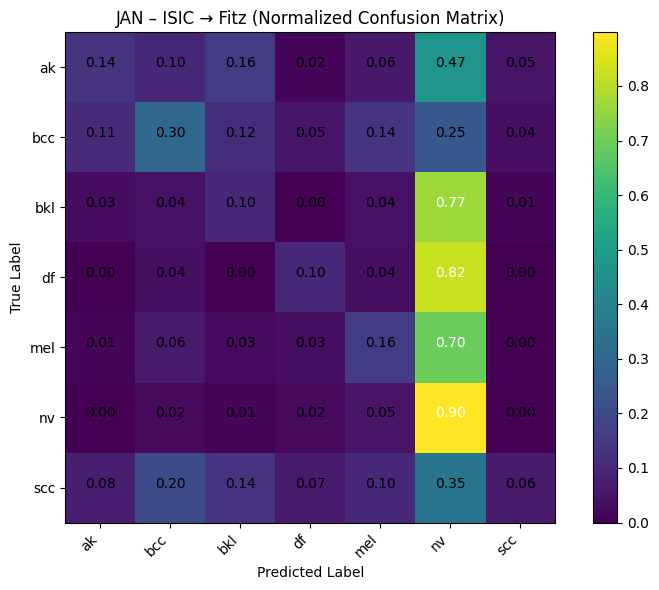

In [ ]:
plt.figure(figsize=(8, 6))
plt.imshow(cm_norm)
plt.colorbar()

plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
plt.yticks(range(len(class_names)), class_names)

for i in range(len(class_names)):
    for j in range(len(class_names)):
        plt.text(j, i, f"{cm_norm[i, j]:.2f}",
                 ha="center",
                 color="white" if cm_norm[i, j] > 0.5 else "black")

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("JAN – ISIC → Fitz (Normalized Confusion Matrix)")
plt.tight_layout()
plt.show()


In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
def collect_predictions_per_class(
    model,
    loader,
    device,
    samples_per_class=5
):
    model.eval()

    class_names = loader.dataset.classes
    n_classes = len(class_names)

    results = {i: [] for i in range(n_classes)}

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            logits, _ = model(images)
            preds = logits.argmax(1).cpu().numpy()

            for img, true_y, pred_y in zip(images.cpu(), labels.numpy(), preds):
                if len(results[true_y]) < samples_per_class:
                    results[true_y].append((img, true_y, pred_y))

            # stop early if all classes filled
            if all(len(v) >= samples_per_class for v in results.values()):
                break

    return results, class_names


In [ ]:
def visualize_predictions_per_class(
    results,
    class_names,
    samples_per_class=5
):
    n_classes = len(class_names)

    plt.figure(figsize=(samples_per_class * 3, n_classes * 3))

    idx = 1
    for class_id in range(n_classes):
        for img, true_y, pred_y in results[class_id]:
            plt.subplot(n_classes, samples_per_class, idx)

            img = img.permute(1, 2, 0).numpy()
            img = np.clip(img, 0, 1)

            plt.imshow(img)
            plt.axis("off")

            title_color = "green" if true_y == pred_y else "red"
            plt.title(
                f"T: {class_names[true_y]}\nP: {class_names[pred_y]}",
                color=title_color,
                fontsize=9
            )
            idx += 1

    plt.tight_layout()
    plt.show()


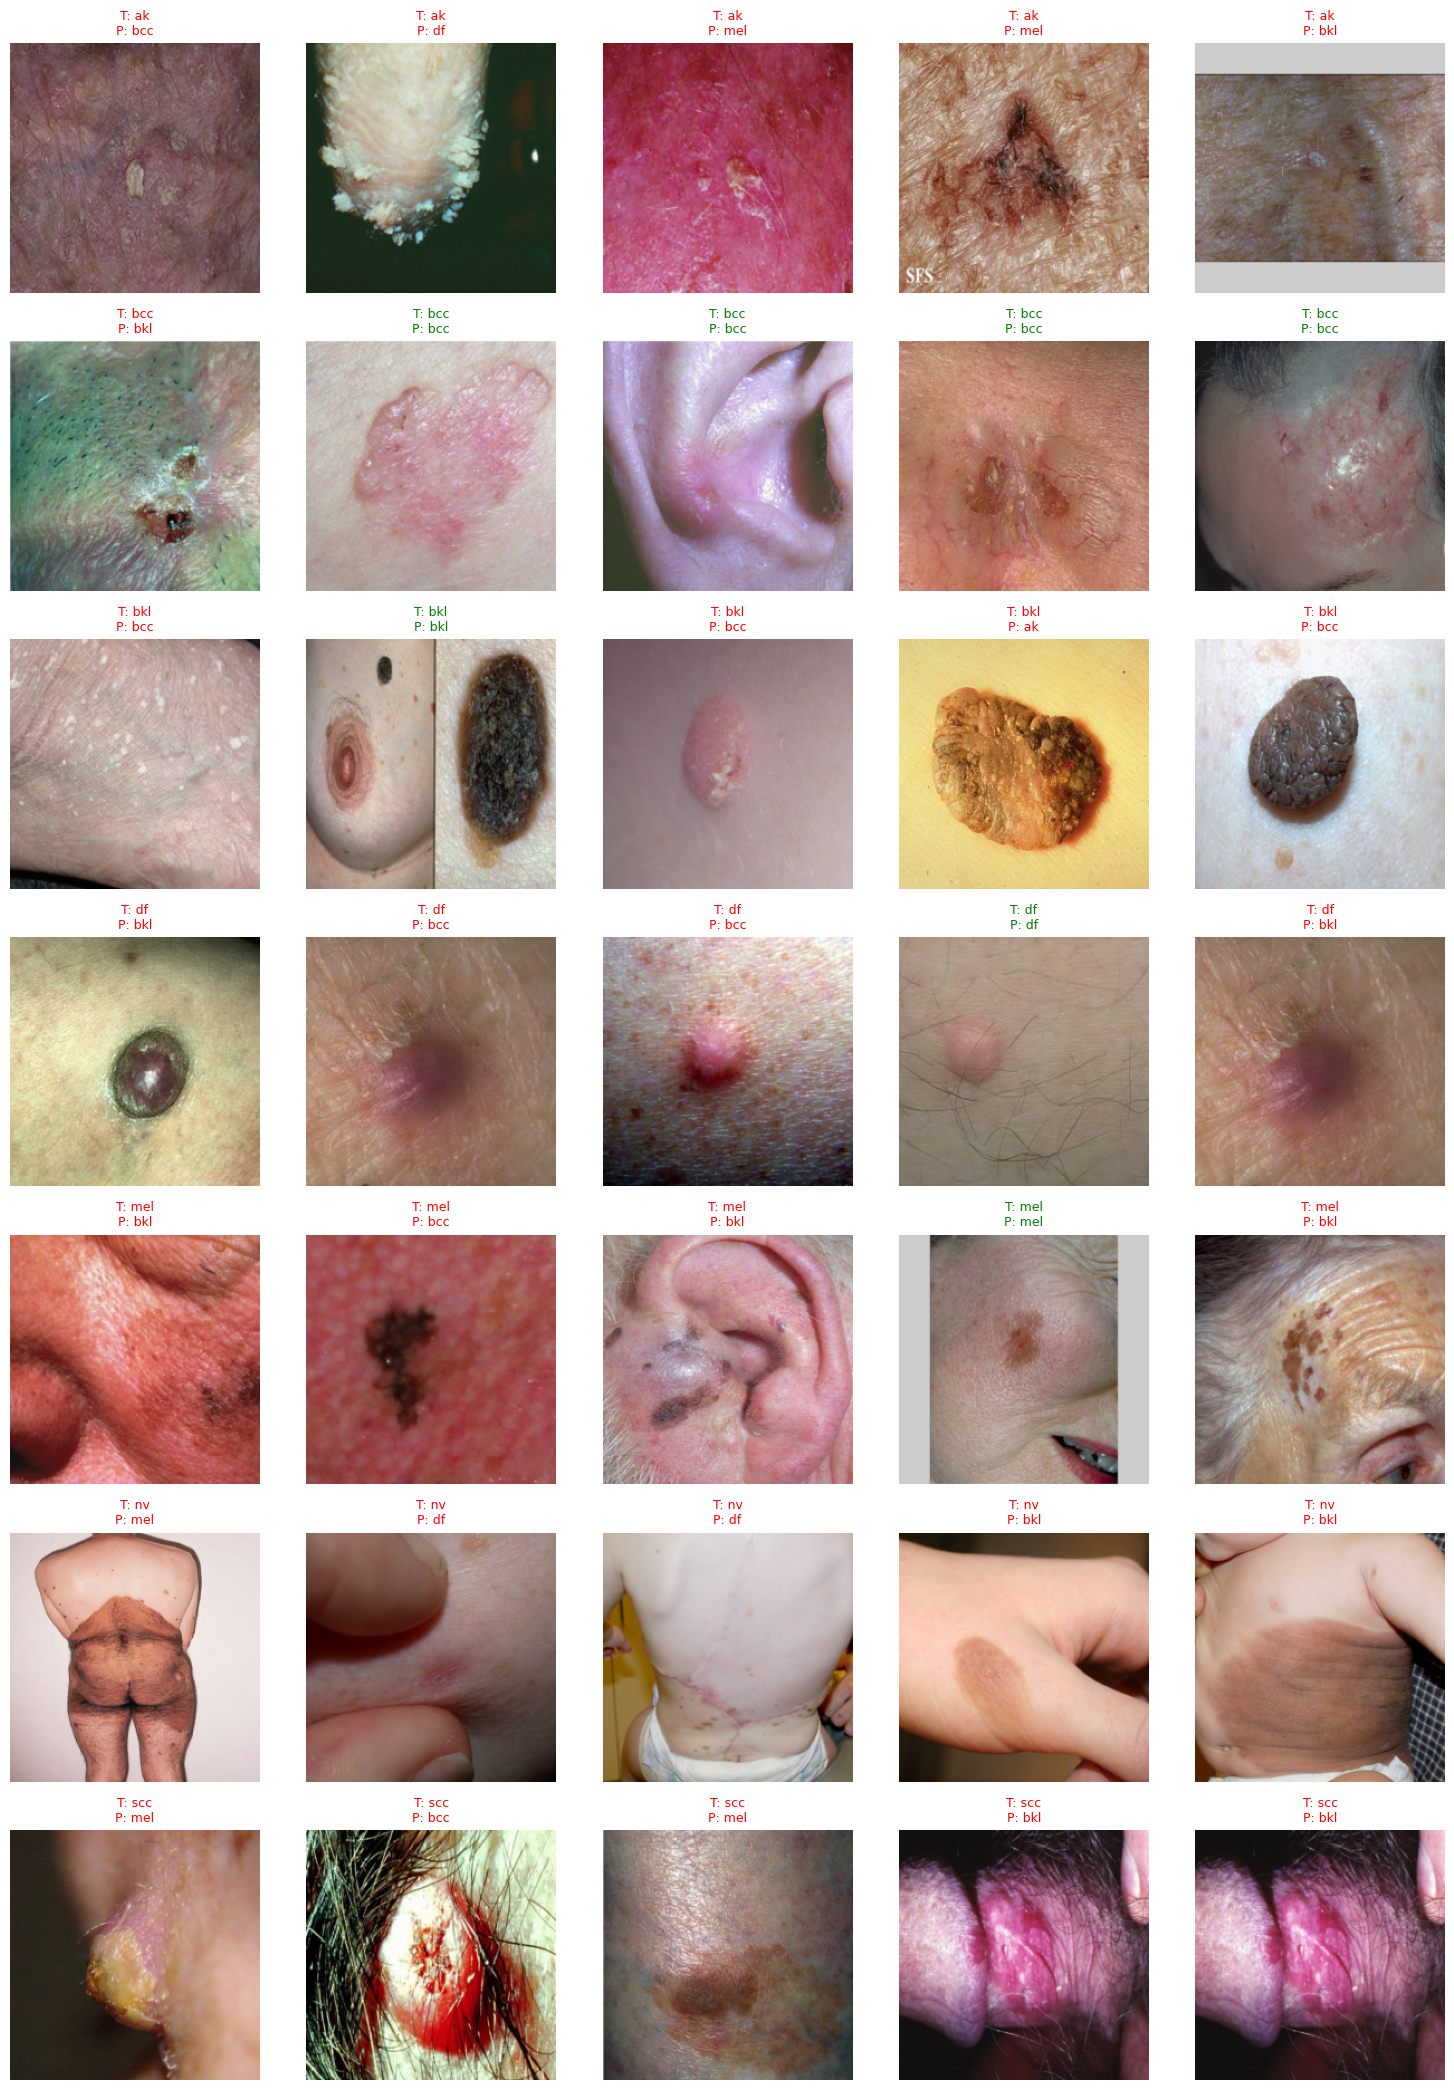

In [ ]:
results, class_names = collect_predictions_per_class(
    model,
    loaders["test"],
    device,
    samples_per_class=5
)

visualize_predictions_per_class(
    results,
    class_names,
    samples_per_class=5
)
